# Rule examples: PCA loadings and prediction weights

## Setup

In [1]:
from pathlib import Path
import sys

import pandas as pd

ROOT = next(
    folder for folder in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (folder / "result_summary" / "data_helper.py").exists()
)
sys.path[:0] = [
    str(ROOT / "result_summary"),
    str(ROOT / "result_summary" / "complex_rules" / "scripts"),
    str(ROOT / "result_summary" / "differential_rules" / "scripts"),
    str(ROOT / "result_summary" / "rule_space"),
    str(ROOT / "result_summary" / "label_prediction"),
]

import final_figures_vis as fv
import prediction_search as ps
import prediction_vis as pv
import rule_examples_helper as ex
import rule_space_helper as rs
import run_predictions as rp
import vis_helper as vh

The drawing settings are those of `rule_examples`; the PCA settings those of `rule_space`, so the loadings are the same.

In [2]:
NETWORK = False
VERTICAL = False
WIDTH = fv.PANEL_INCHES * (5 if NETWORK else 4)
DOT = 6
FONT_SIZE = 20
N_TOP = 10
N_RULES = 4
ONLY_400 = True
END_COLORS = fv.stage_tags(["Control", "Severe"], 2)
PREDICTION_COLORS = fv.RESPONSE_TAGS
METRICS = ["Kind", "Support", "Confidence", "Lift", "Leverage", "Conviction", "Individual_FDR"]

STAGES = ["Control", "Severe"]
EXCLUDE = ["Muscle"]
MIN_FOV = 0.05

rs.METRIC = "Lift"
rs.POSITIVE_ONLY = False
rs.RULE_MAX_ITEMS = 2
rs.NO_SELF = False

## Data

In [3]:
data = ex.load()
cell_colors = vh.set_cell_colors(data.cells)
pca_data = rs.load()
_, prediction_fovs = ps.load_fovs()
sizes = data.fovs.set_index("FOV")["Size [um]"]

Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71
Read results_CN_pairwise.csv
Loaded 15660 rules.
Kept 6978 rules at FDR <= 0.05.
Kept 6946 rules naming no Unidentified.
Kept 6946 rules (max_items=2, kind=None).
Read results_CN_pairwise.csv
Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71
Read results_CN_pairwise.csv + results_CN_complex.csv
Loaded 758621 rules.
Kept 6978 rules at FDR <= 0.05.
Kept 6946 rules naming no Unidentified.
Kept 6946 rules (max_items=4, kind=None).
Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71


## Picking and drawing

In [4]:
def kept(fovs):
    """`fovs`, only the 400 um ones with ONLY_400."""
    fovs = pd.Index(fovs)
    return fovs[sizes.reindex(fovs).eq(400)] if ONLY_400 else fovs


def draw(name, picks, examples, end_colors):
    """The examples of `ex.pick_by_weight`, drawn in one panel per rule by `fv.plot_rule_examples` (as columns
    with VERTICAL) under their `ex.metrics`, tagged in their end's colour (its key saved as keys/ends_<name>);
    a table of the picks."""
    fv.save_group_key(end_colors, FONT_SIZE, f"ends_{name}")
    key = fv.key_cells(data.cells, [fov for *_, sides in examples.values() for fov, *_ in sides], data.passed, N_TOP)
    fv.plot_rule_examples(data.cells, examples, data.passed, cell_colors, key, width=WIDTH, font_size=FONT_SIZE,
                          network=NETWORK, vertical=VERTICAL, dot=DOT,
                          notes={rule: "\n".join([rule] + [ex.metrics(data, fov, pair, METRICS) for fov, *_ in sides])
                                 for rule, (pair, _, sides) in examples.items()},
                          save=f"weight_examples{'_vertical' if VERTICAL else ''}/{name}")
    return picks


def pca_examples(organ, score, pc=None, far=None):
    """For one organ's rule PCA by `score`, fitted as in `rule_space` (without the FOVs over `far` times the
    usual distance from its middle when given): the N_RULES rules with the biggest loadings on `pc` (its better
    PC when None), each of its median kind, by `ex.pick_by_weight`: a FOV with the rule from the end of the PC
    that having it pulls toward and one without it from the other, shared by as many rules as can be, the
    furthest toward its end among equals; the STAGES[0] end first."""
    rs.SCORE_COL = score
    fit = lambda fovs=None: rs.run(pca_data, stages=STAGES, organs=[organ], exclude=EXCLUDE,
                                   min_fov=MIN_FOV, fovs=fovs, diagnostics=False)
    scope = fit()
    if far:
        scope = fit(rs.outliers(scope, far)[0])
    pc = pc or max(("PC1", "PC2"), key=lambda pc: rs.stage_auc(scope, pc, *STAGES))
    loadings = pd.Series(scope.model.components_[int(pc[2:]) - 1], index=scope.matrix.columns)
    loadings = loadings.sort_values(key=abs, ascending=False)
    weights = pd.DataFrame({"kind": ex.median_kinds(pca_data.results, scope.matrix.index)[loadings.index],
                            "weight": loadings}).rename_axis("rule").reset_index()
    weights["pull"] = weights["kind"].map(ex.pull)
    coords = scope.coords.set_index("FOV")
    place, stage = coords[pc], coords[score]
    severe = 1 if place[stage.eq(STAGES[-1])].mean() > place[stage.eq(STAGES[0])].mean() else -1
    ends = {-severe: (f"{pc}, {STAGES[0]} side", kept(place.index), END_COLORS[0]),
            severe: (f"{pc}, {STAGES[-1]} side", kept(place.index), END_COLORS[1])}
    name = f"pca_{organ}_{score.split()[0]}_{pc}" + ("_no_outliers" if far else "")
    return draw(name, *ex.pick_by_weight(data, weights, ends, N_RULES, place))


def prediction_examples(prediction, unit="patient"):
    """For one saved prediction: the N_RULES rules of its best run with the biggest weights, by
    `ex.pick_by_weight`: a FOV with the rule from the group that having it pulls toward and one without it
    from the other, shared by as many rules as can be; the "+" group first."""
    saved = pd.read_csv(ps.output_path(prediction, "weights", unit))
    rules, kinds = zip(*saved["rule"].map(pv.plain_rule))
    weights = pd.DataFrame({"rule": rules, "kind": kinds, "weight": saved["weight"],
                            "pull": [ex.pull(kind, feature) for kind, feature in zip(kinds, saved["feature"])]})
    fovs = ps.patients_of(prediction, data.cells, prediction_fovs)
    side = fovs.set_index("FOV")["side"]
    ends = {1: (fovs["positive"].iloc[0], kept(side.index[side.eq(1)]), PREDICTION_COLORS[0]),
            -1: (fovs["negative"].iloc[0], kept(side.index[side.eq(0)]), PREDICTION_COLORS[1])}
    return draw(f"prediction_{ps.name_of(prediction)}_{unit}", *ex.pick_by_weight(data, weights, ends, N_RULES))

## PCA loadings

### Duodenum · Pathological score · PC2

Duodenum, Control vs Severe: 62 FOVs x 63 columns  |  PC1 16.0%  PC2 9.1%
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_pca_Duodenum_Pathological_PC2.pdf


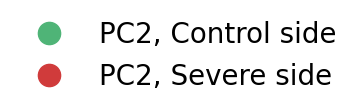

attracts_Epithelial_to_Goblet
Control_07_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.181        0.77 2.499     0.109        3.01           0.004
Control_06_FOV_2
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\pca_Duodenum_Pathological_PC2\attracts_Epithelial_to_Goblet.pdf
saved attracts_Epithelial_to_Goblet_1, attracts_Epithelial_to_Goblet_2, attracts_Epithelial_to_Goblet_3, attracts_Epithelial_to_Goblet_4, attracts_Epithelial_to_Goblet_5, attracts_Epithelial_to_Goblet_6, attracts_Epithelial_to_Goblet_7, attracts_Epithelial_to_Goblet_8 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\pca_Duodenum_Pathological_PC2


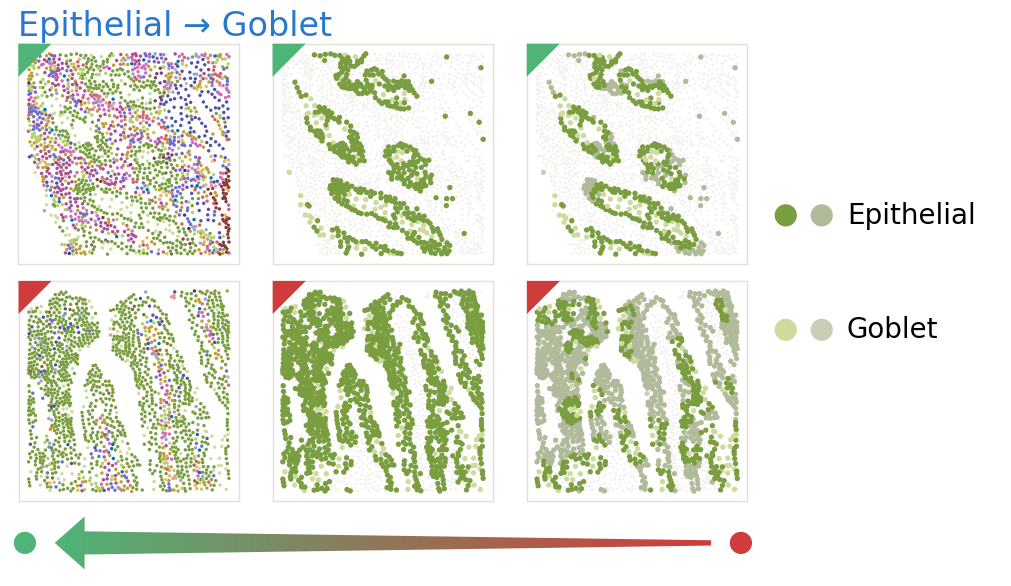

attracts_Goblet_to_Epithelial
Control_07_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.037       0.985 1.443     0.011      21.248           0.007
GVHD_57_FOV_3
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\pca_Duodenum_Pathological_PC2\attracts_Goblet_to_Epithelial.pdf
saved attracts_Goblet_to_Epithelial_1, attracts_Goblet_to_Epithelial_2, attracts_Goblet_to_Epithelial_3, attracts_Goblet_to_Epithelial_4, attracts_Goblet_to_Epithelial_5, attracts_Goblet_to_Epithelial_6, attracts_Goblet_to_Epithelial_7, attracts_Goblet_to_Epithelial_8 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\pca_Duodenum_Pathological_PC2


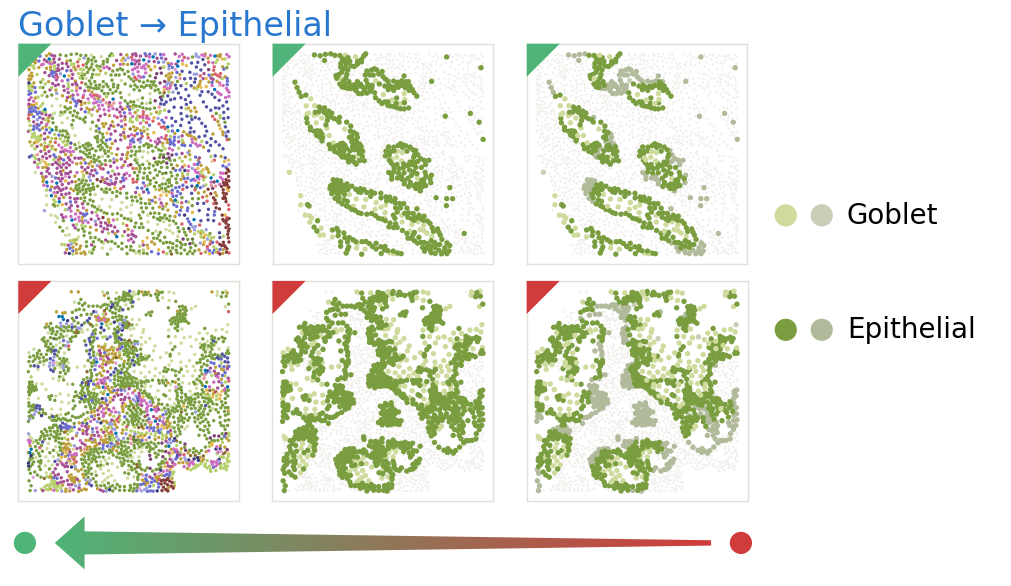

avoids_CD4T_to_Goblet
Control_07_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.003       0.041 0.133    -0.022       0.721           0.007
Control_02_FOV_3
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\pca_Duodenum_Pathological_PC2\avoids_CD4T_to_Goblet.pdf
saved avoids_CD4T_to_Goblet_1, avoids_CD4T_to_Goblet_2, avoids_CD4T_to_Goblet_3, avoids_CD4T_to_Goblet_4, avoids_CD4T_to_Goblet_5, avoids_CD4T_to_Goblet_6, avoids_CD4T_to_Goblet_7, avoids_CD4T_to_Goblet_8 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\pca_Duodenum_Pathological_PC2


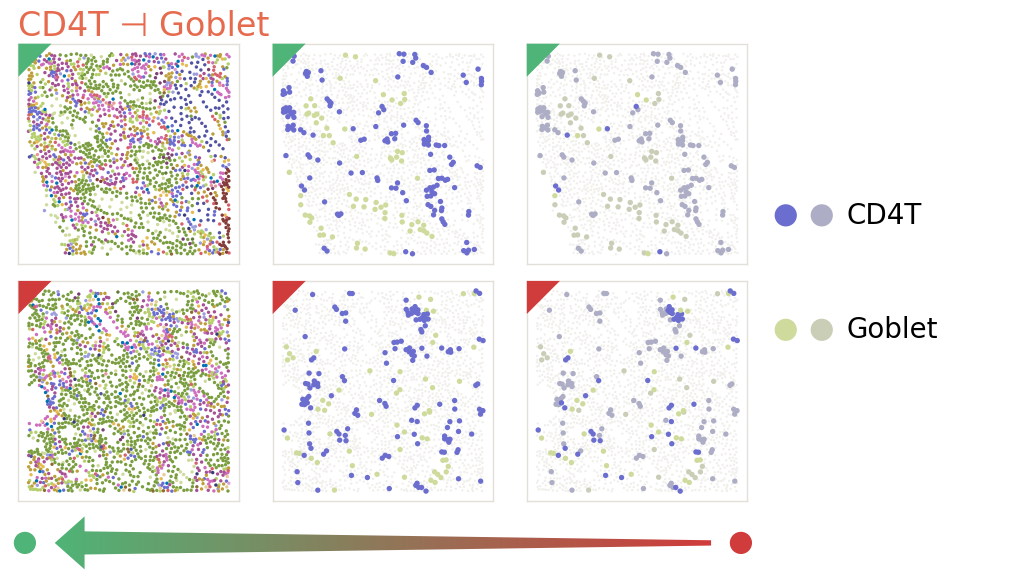

attracts_Plasma_to_Plasma_CD38
Control_07_FOV_2
not mined in this FOV
GVHD_57_FOV_3
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.027       0.581 2.709     0.017       1.874           0.006
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\pca_Duodenum_Pathological_PC2\attracts_Plasma_to_Plasma_CD38.pdf
saved attracts_Plasma_to_Plasma_CD38_1, attracts_Plasma_to_Plasma_CD38_2, attracts_Plasma_to_Plasma_CD38_3, attracts_Plasma_to_Plasma_CD38_4, attracts_Plasma_to_Plasma_CD38_5, attracts_Plasma_to_Plasma_CD38_6, attracts_Plasma_to_Plasma_CD38_7, attracts_Plasma_to_Plasma_CD38_8 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\pca_Duodenum_Pathological_PC2


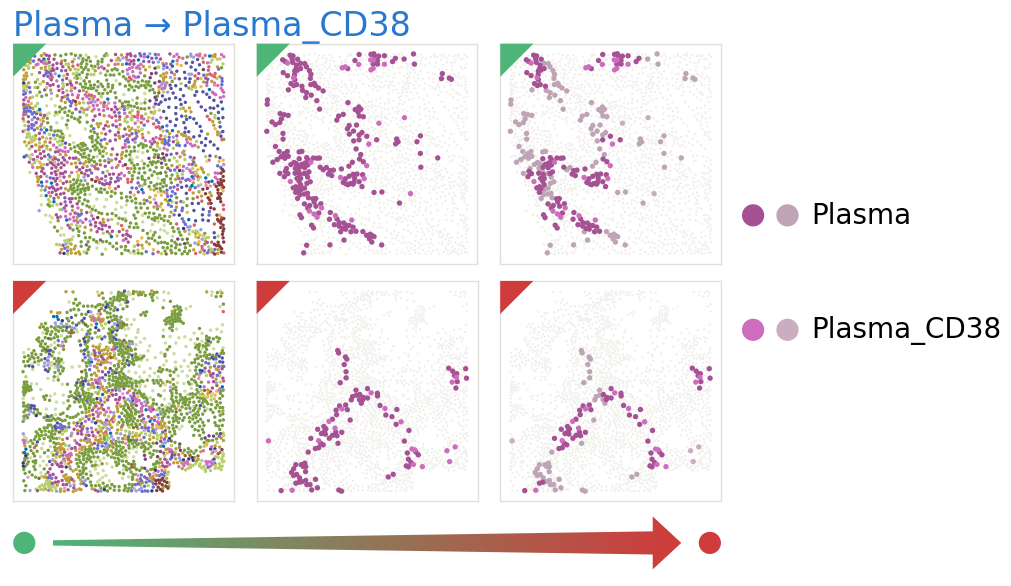

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\pca_Duodenum_Pathological_PC2\cells.pdf


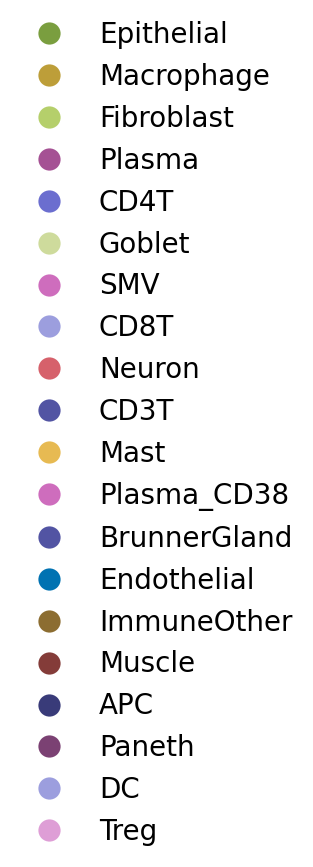

,kind,rule,group,has rule,FOV,rarer cell type's cells,weight
0,attracts,Epithelial -> Goblet,"PC2, Control side",True,Control_07_FOV_2,68,0.293293
1,attracts,Epithelial -> Goblet,"PC2, Severe side",False,Control_06_FOV_2,77,0.293293
2,attracts,Goblet -> Epithelial,"PC2, Control side",True,Control_07_FOV_2,68,0.267407
3,attracts,Goblet -> Epithelial,"PC2, Severe side",False,GVHD_57_FOV_3,179,0.267407
4,avoids,CD4T -> Goblet,"PC2, Control side",True,Control_07_FOV_2,68,-0.242397
5,avoids,CD4T -> Goblet,"PC2, Severe side",False,Control_02_FOV_3,55,-0.242397
6,attracts,Plasma -> Plasma_CD38,"PC2, Control side",False,Control_07_FOV_2,25,-0.225443
7,attracts,Plasma -> Plasma_CD38,"PC2, Severe side",True,GVHD_57_FOV_3,18,-0.225443


In [5]:
pca_examples("Duodenum", "Pathological score", pc="PC2")

## Prediction weights

### Steroid response without Muscle rules

skipped Plasma -> Plasma (attracts): no has-rule table for it
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_prediction_cortico_response_no_muscle_rules_patient.pdf


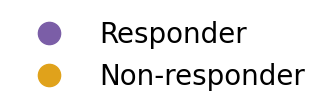

attracts_SMV_to_Fibroblast
GVHD_30_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.106       0.947 1.274     0.023       4.856           0.004
GVHD_51_FOV_3
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\prediction_cortico_response_no_muscle_rules_patient\attracts_SMV_to_Fibroblast.pdf
saved attracts_SMV_to_Fibroblast_1, attracts_SMV_to_Fibroblast_2, attracts_SMV_to_Fibroblast_3, attracts_SMV_to_Fibroblast_4, attracts_SMV_to_Fibroblast_5, attracts_SMV_to_Fibroblast_6, attracts_SMV_to_Fibroblast_7, attracts_SMV_to_Fibroblast_8 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\prediction_cortico_response_no_muscle_rules_patient


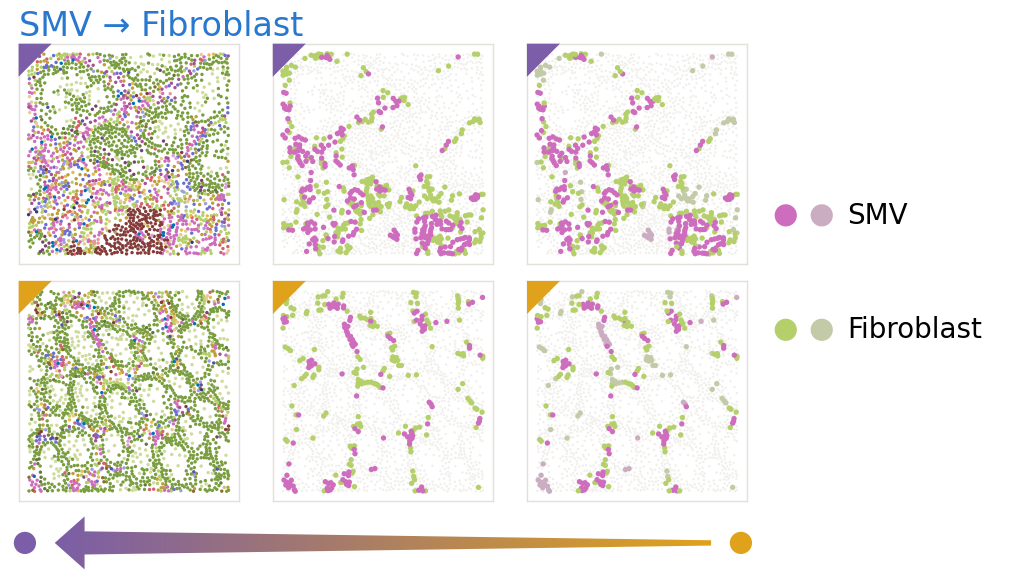

attracts_SMV_to_Endothelial
GVHD_30_FOV_2
not mined in this FOV
GVHD_51_FOV_3
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts     0.03       0.547 2.561     0.018       1.736           0.007
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\prediction_cortico_response_no_muscle_rules_patient\attracts_SMV_to_Endothelial.pdf
saved attracts_SMV_to_Endothelial_1, attracts_SMV_to_Endothelial_2, attracts_SMV_to_Endothelial_3, attracts_SMV_to_Endothelial_4, attracts_SMV_to_Endothelial_5, attracts_SMV_to_Endothelial_6, attracts_SMV_to_Endothelial_7, attracts_SMV_to_Endothelial_8 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\prediction_cortico_response_no_muscle_rules_patient


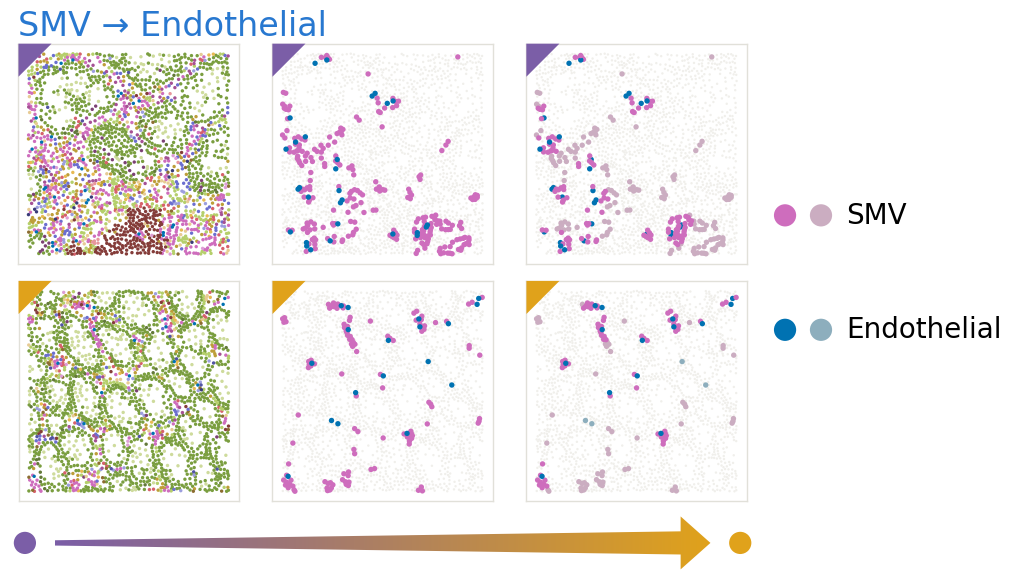

attracts_Goblet_to_Epithelial
GVHD_30_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.042         1.0 1.623     0.016         inf           0.004
GVHD_51_FOV_3
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\prediction_cortico_response_no_muscle_rules_patient\attracts_Goblet_to_Epithelial.pdf
saved attracts_Goblet_to_Epithelial_1, attracts_Goblet_to_Epithelial_2, attracts_Goblet_to_Epithelial_3, attracts_Goblet_to_Epithelial_4, attracts_Goblet_to_Epithelial_5, attracts_Goblet_to_Epithelial_6, attracts_Goblet_to_Epithelial_7, attracts_Goblet_to_Epithelial_8 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\prediction_cortico_response_no_muscle_rules_patient


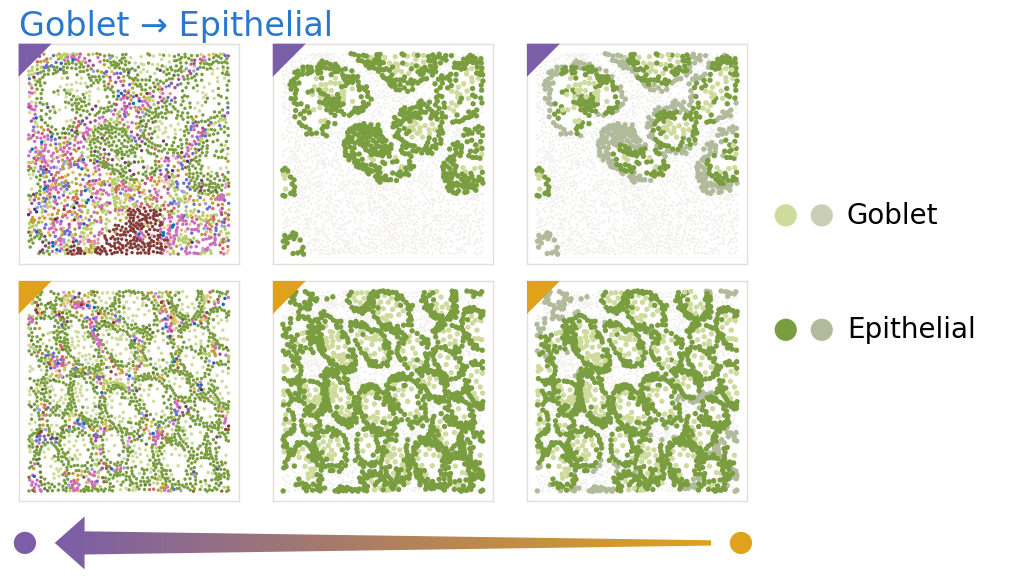

attracts_Epithelial_to_Goblet
GVHD_30_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.152       0.524 2.334     0.087       1.628           0.004
GVHD_51_FOV_3
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\prediction_cortico_response_no_muscle_rules_patient\attracts_Epithelial_to_Goblet.pdf
saved attracts_Epithelial_to_Goblet_1, attracts_Epithelial_to_Goblet_2, attracts_Epithelial_to_Goblet_3, attracts_Epithelial_to_Goblet_4, attracts_Epithelial_to_Goblet_5, attracts_Epithelial_to_Goblet_6, attracts_Epithelial_to_Goblet_7, attracts_Epithelial_to_Goblet_8 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\prediction_cortico_response_no_muscle_rules_patient


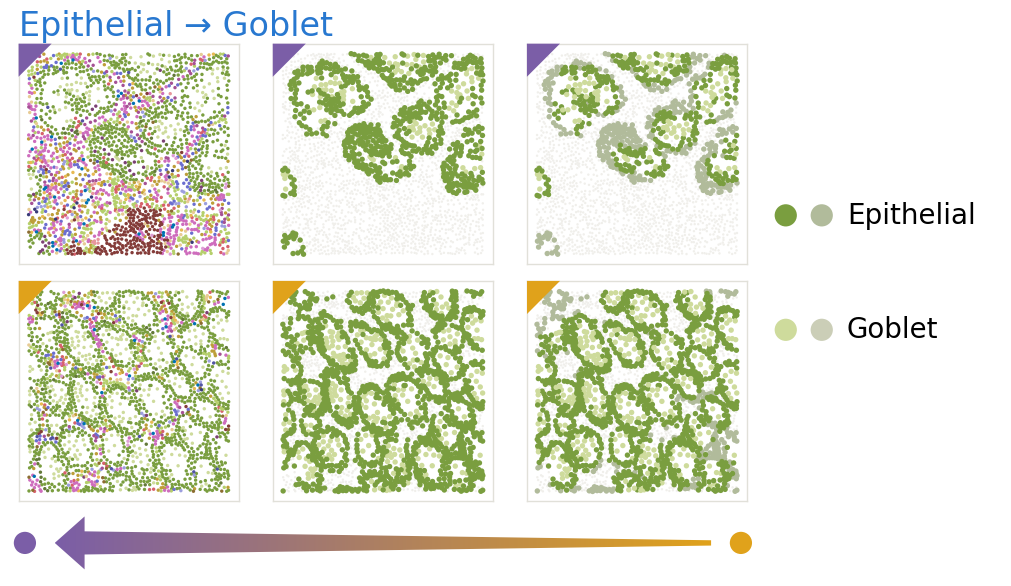

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\weight_examples\prediction_cortico_response_no_muscle_rules_patient\cells.pdf


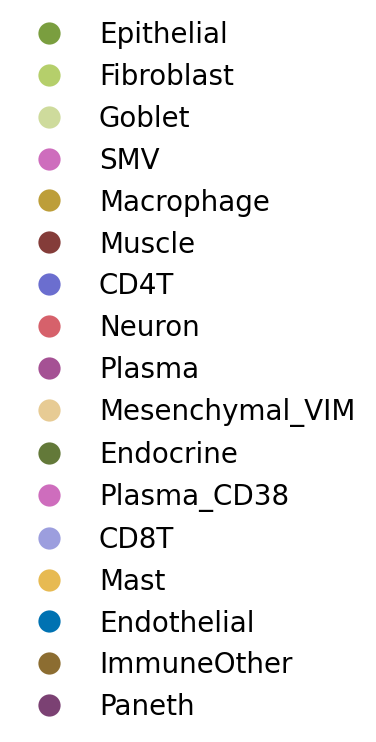

,kind,rule,group,has rule,FOV,rarer cell type's cells,weight
0,attracts,SMV -> Fibroblast,Responder,True,GVHD_30_FOV_2,246,2.174907
1,attracts,SMV -> Fibroblast,Non-responder,False,GVHD_51_FOV_3,117,2.174907
2,attracts,SMV -> Endothelial,Responder,False,GVHD_30_FOV_2,29,-1.756934
3,attracts,SMV -> Endothelial,Non-responder,True,GVHD_51_FOV_3,18,-1.756934
4,attracts,Goblet -> Epithelial,Responder,True,GVHD_30_FOV_2,94,1.197502
5,attracts,Goblet -> Epithelial,Non-responder,False,GVHD_51_FOV_3,282,1.197502
6,attracts,Epithelial -> Goblet,Responder,True,GVHD_30_FOV_2,94,0.874516
7,attracts,Epithelial -> Goblet,Non-responder,False,GVHD_51_FOV_3,282,0.874516


In [6]:
prediction_examples({**rp.CORTICO, "without_muscle_rules": True})